# Proyek Analisis Data: E-Commerce
- **Nama:** Bagus Uswanto
- **Email:** DS013B6Y0318@student.devacademy.id
- **ID Dicoding:** DS013B6Y0318

Analisis deskriptif terhadap CSV lokal yang disediakan untuk submission Dicoding. Struktur mengikuti templat resmi; data mentah dipertahankan dan setiap tahap dapat dijalankan ulang. Nilai barang memakai BRL, bukan laba atau total pembayaran. Hasil berikut merupakan observasi dataset historis, dengan status pesanan pada snapshot sumber.

## Menentukan Pertanyaan Bisnis

Pertanyaan menggunakan **Specific, Measurable, Action-Oriented, Relevant, dan Time-bound**. Periode pembelian utama adalah **1 Januari 2017–31 Agustus 2018**, dengan batas akhir eksklusif 1 September 2018. Periode ini menghindari ekor transaksi 2016 dan September–Oktober 2018 yang sangat jarang; pemilihan tersebut tidak membuktikan setiap bulan sumber tercatat lengkap.

| Q | Specific | Measurable | Action-Oriented | Relevant | Time-bound |
|---|---|---|---|---|---|
| Q1 | Kategori produk pada order delivered | Nilai barang BRL, kontribusi, item, order unik dan tren bulanan | Pilih kategori prioritas katalog/pemasaran | Alokasi perhatian pada kategori bernilai besar | Pembelian 1 Jan 2017–31 Agu 2018 |
| Q2 | Ketepatan pengiriman dan review pelanggan menurut state | Lateness rate, proporsi skor 1–2, selisih persentase poin, n | Prioritaskan pemeriksaan operasional wilayah | Pengalaman pengiriman dan ulasan | Pembelian 1 Jan 2017–31 Agu 2018 |
| Q3 | Pelanggan unik dan perilaku pembelian ulang | Recency hari, frequency order unik, monetary BRL serta segmen | Pilih pilot retensi/pembelian ulang | Strategi berbeda untuk pembeli sekali dan berulang | Observasi 1 Jan 2017–31 Agu 2018; acuan 1 Sep 2018 |

- **Q1:** Selama 1 Januari 2017–31 Agustus 2018, lima kategori produk mana yang menyumbang nilai penjualan barang terbesar pada pesanan delivered, berapa kontribusinya terhadap total, dan bagaimana tren bulanan kelima kategori tersebut?
- **Q2:** Untuk pesanan delivered yang dibeli pada 1 Januari 2017–31 Agustus 2018, seberapa berbeda proporsi ulasan buruk pada pengiriman terlambat dan tepat waktu, serta negara bagian pelanggan mana yang perlu diprioritaskan berdasarkan keterlambatan dan ulasan buruk?
- **Q3:** Dengan tanggal acuan 1 September 2018 dan periode pembelian 1 Januari 2017–31 Agustus 2018, bagaimana pelanggan delivered tersebar menurut recency, frequency dan monetary, serta segmen mana yang dapat diprioritaskan untuk retensi/pembelian ulang?

**Definisi utama:** price item dijumlahkan sebagai integer sen BRL; freight tidak masuk monetary. Terlambat berarti tanggal kalender penerimaan melewati estimasi. Skor 1–2 disebut ulasan buruk. Identitas pelanggan memakai customer_unique_id. Hasil Q2 bersifat hubungan teramati dan tidak membuktikan sebab-akibat.

## Import Semua Packages/Library yang Digunakan

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import platform
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "src/config.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Jalankan kernel notebook dari root proyek atau subdirektorinya.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.config import (PRIMARY_SOURCES, ANALYSIS_START, ANALYSIS_END_EXCLUSIVE,
                        RFM_REFERENCE_DATE, RFM_SEGMENTS, MIN_STATE_SAMPLE)
from src.data_pipeline import (load_source, clean_orders, clean_customers, clean_translation,
    clean_products, clean_order_items, clean_reviews, build_analysis_tables)
from src.data_assessment import profile_source
from src.analytics import analyze_q1, analyze_q2, build_rfm, analyze_q3
from src.charts import (plot_top_categories, plot_monthly_categories, plot_bad_reviews,
    plot_state_priority, plot_rfm_distributions, plot_rfm_segments, save_figure, number, brl)

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                    "figure.facecolor": "white", "axes.facecolor": "white"})
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.max_rows", 30)
FIGURE_DIR = ROOT / "reports/figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
baseline = json.loads((ROOT / "reports/baseline.json").read_text())
reference_results = json.loads((ROOT / "reports/analytical_results.json").read_text())
quality_report = json.loads((ROOT / "reports/data_quality.json").read_text())
cleaning_report = json.loads((ROOT / "reports/cleaning_audit.json").read_text())

# Baseline dicek sebelum membaca; notebook tidak mengunduh atau menulis ulang CSV.
def sha(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
for entry in baseline["source_files"]:
    assert sha(ROOT / entry["path"]) == entry["sha256"]
assert sha(ROOT / baseline["template"]["path"]) == baseline["template"]["sha256"]
assert platform.python_version() == "3.12.13", "Gunakan runtime proyek yang dicatat pada README."
display(pd.DataFrame([{"Python": platform.python_version(), "pandas": pd.__version__,
                       "NumPy": np.__version__, "Matplotlib": matplotlib.__version__}]))

,Python,pandas,NumPy,Matplotlib
0,3.12.13,3.1.0,2.5.4,3.11.2


## Data Wrangling

### Gathering Data

#### Muat sumber utama dan catat cakupan
Enam CSV utama dibaca melalui loader bersama sebagai string agar ID, kode pos, dan representasi desimal tidak berubah. Tiga sumber pendukung dicatat dalam inventaris; pembayaran, penjual, dan geolocation tidak diperlukan untuk menjawab Q1–Q3. Tabel berikut membedakan sumber yang dimuat dari sumber yang hanya diinventarisasi.

In [2]:
raw_tables = {name: load_source(name) for name in PRIMARY_SOURCES}
inventory = pd.DataFrame([{"file": e["path"], "peran": e["role"], "baris sumber": e["row_count"],
                           "kolom": len(e["columns"]), "dimuat analisis": Path(e["path"]).stem in PRIMARY_SOURCES}
                          for e in baseline["source_files"]])
display(inventory)
for name, frame in raw_tables.items():
    display(Markdown(f"**{name}: {number(len(frame))} baris × {len(frame.columns)} kolom**"))
    display(frame.head(3))
    assert len(frame) == next(e["row_count"] for e in baseline["source_files"]
                              if Path(e["path"]).stem == name)

,file,peran,baris sumber,kolom,dimuat analisis
0,data/orders_dataset.csv,primary,99441,8,True
1,data/customers_dataset.csv,primary,99441,5,True
2,data/order_items_dataset.csv,primary,112650,7,True
3,data/products_dataset.csv,primary,32951,9,True
4,data/order_reviews_dataset.csv,primary,99224,7,True
5,data/product_category_name_translation.csv,primary,71,2,True
6,data/order_payments_dataset.csv,supporting,103886,5,False
7,data/sellers_dataset.csv,supporting,3095,4,False
8,data/geolocation_dataset.csv,supporting,1000163,5,False


**orders_dataset: 99.441 baris × 8 kolom**

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


**customers_dataset: 99.441 baris × 5 kolom**

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP


...

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40,287,1,225,16,10,14
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44,276,1,1000,30,18,20
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46,250,1,154,18,9,15


**order_reviews_dataset: 99.224 baris × 7 kolom**

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,<NA>,<NA>,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,<NA>,<NA>,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,<NA>,<NA>,2018-02-17 00:00:00,2018-02-18 14:36:24


**product_category_name_translation: 71 baris × 2 kolom**

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


**Insight Gathering:** tabel memiliki grain berbeda: orders per pesanan, items per pasangan order/item, customers per customer_id, dan reviews dapat berisi beberapa baris per pesanan. Penggabungan item dengan review atau pembayaran mentah berisiko menggandakan nilai barang. Analisis wilayah cukup memakai customer_state; satu juta baris geolocation tidak perlu dimuat. Identitas lintas pembelian memakai customer_unique_id, bukan customer_id.

### Assessing Data

#### Periksa nilai kosong, kunci, parsing, kronologi, dan cakupan
Profil berikut dihitung ulang dari enam tabel mentah. Field kosong dan teks hanya whitespace diperlakukan sebagai missing dalam assessment, tanpa mengubah nilai sumber. Issue register mencakup temuan sumber utama dan profil pendukung P02 yang terikat hash baseline.

In [3]:
profiles = {name: profile_source(name, frame) for name, frame in raw_tables.items()}
for name, profile in profiles.items():
    for key, value in profile.items():
        assert value == quality_report["profiles"][name][key], (name, key)
missing_rows = [{"sumber": name, "kolom": col, "field kosong": profile["empty_field_counts"][col],
                 "missing termasuk whitespace": n}
                for name, profile in profiles.items()
                for col, n in profile["missing_including_whitespace"].items() if n]
display(pd.DataFrame(missing_rows))
key_rows = [{"sumber": name, **profile["key"]} for name, profile in profiles.items() if "key" in profile]
display(pd.DataFrame(key_rows)[["sumber", "columns", "rows_with_missing_key", "additional_duplicate_keys", "unique_and_complete"]])
review_raw = raw_tables["order_reviews_dataset"]
display(pd.DataFrame([{"duplikasi persis tambahan": int(review_raw.duplicated().sum()),
    "review_id berulang tambahan": int(review_raw["review_id"].duplicated().sum()),
    "order dengan beberapa review": int(review_raw.groupby("order_id").size().gt(1).sum()),
    "pasangan review/order berulang": int(review_raw.duplicated(["review_id", "order_id"]).sum())}]))
issues = pd.DataFrame(quality_report["issues"])
display(issues[["issue_id", "source", "kind", "affected_count", "affected_unit"]])

,sumber,kolom,field kosong,missing termasuk whitespace
0,orders_dataset,order_approved_at,160,160
1,orders_dataset,order_delivered_carrier_date,1783,1783
2,orders_dataset,order_delivered_customer_date,2965,2965
3,products_dataset,product_category_name,610,610
4,products_dataset,product_name_lenght,610,610
5,products_dataset,product_description_lenght,610,610
6,products_dataset,product_photos_qty,610,610
7,products_dataset,product_weight_g,2,2
8,products_dataset,product_length_cm,2,2
9,products_dataset,product_height_cm,2,2


,sumber,columns,rows_with_missing_key,additional_duplicate_keys,unique_and_complete
0,orders_dataset,[order_id],0,0,True
1,customers_dataset,[customer_id],0,0,True
2,order_items_dataset,"[order_id, order_item_id]",0,0,True
3,products_dataset,[product_id],0,0,True
4,product_category_name_translation,[product_category_name],0,0,True


,duplikasi persis tambahan,review_id berulang tambahan,order dengan beberapa review,pasangan review/order berulang
0,0,814,547,0


,issue_id,source,kind,affected_count,affected_unit
0,DQ01,products_dataset,missing_category,610,products
1,DQ02,products_dataset,missing_translation,13,products
2,DQ03,order_reviews_dataset,multiple_reviews_per_order,547,orders
3,DQ04,order_reviews_dataset,repeated_review_id,814,additional_rows
4,DQ05,orders_dataset,missing_lifecycle_date,2965,orders
5,DQ06,orders_dataset,missing_lifecycle_date,1783,orders
6,DQ07,orders_dataset,missing_lifecycle_date,160,orders
7,DQ08,order_reviews_dataset,optional_text_missing,87658,review_rows
8,DQ09,order_reviews_dataset,optional_text_missing,58274,review_rows
9,DQ10,products_dataset,missing_optional_product_attributes,611,products


In [4]:
# Missing date menurut status memisahkan konteks status dari masalah delivered.
status_rows = []
for status, group in raw_tables["orders_dataset"].groupby("order_status"):
    status_rows.append({"status": status, "order": len(group),
        "tanpa approval": int(group["order_approved_at"].isna().sum()),
        "tanpa carrier": int(group["order_delivered_carrier_date"].isna().sum()),
        "tanpa penerimaan": int(group["order_delivered_customer_date"].isna().sum())})
display(pd.DataFrame(status_rows))
checks = []
for name, profile in profiles.items():
    for col, detail in profile["dates"].items():
        checks.append({"sumber": name, "kolom": col, "jenis": "tanggal", "gagal parsing": detail["parse_failures"]})
    for col, detail in profile["numeric"].items():
        checks.append({"sumber": name, "kolom": col, "jenis": "numerik", "gagal parsing": detail["parse_failures"]})
display(pd.DataFrame(checks))
display(pd.DataFrame(quality_report["facts"]["foreign_keys"]).T[["child_rows", "missing_key_rows", "unmatched_nonmissing_rows"]])

,status,order,tanpa approval,tanpa carrier,tanpa penerimaan
0,approved,2,0,2,2
1,canceled,625,141,550,619
2,created,5,5,5,5
3,delivered,96478,14,2,8
4,invoiced,314,0,314,314
5,processing,301,0,301,301
6,shipped,1107,0,0,1107
7,unavailable,609,0,609,609


,sumber,kolom,jenis,gagal parsing
0,orders_dataset,order_purchase_timestamp,tanggal,0
1,orders_dataset,order_approved_at,tanggal,0
2,orders_dataset,order_delivered_carrier_date,tanggal,0
3,orders_dataset,order_delivered_customer_date,tanggal,0
4,orders_dataset,order_estimated_delivery_date,tanggal,0
5,order_items_dataset,shipping_limit_date,tanggal,0
6,order_items_dataset,order_item_id,numerik,0
7,order_items_dataset,price,numerik,0
8,order_items_dataset,freight_value,numerik,0
9,products_dataset,product_name_lenght,numerik,0


,child_rows,missing_key_rows,unmatched_nonmissing_rows
orders_dataset.customer_id -> customers_dataset.customer_id,99441,0,0
order_items_dataset.order_id -> orders_dataset.order_id,112650,0,0
order_items_dataset.product_id -> products_dataset.product_id,112650,0,0
order_items_dataset.seller_id -> sellers_dataset.seller_id,112650,0,0
order_reviews_dataset.order_id -> orders_dataset.order_id,99224,0,0
products_dataset.product_category_name -> product_category_name_translation.product_category_name,32951,610,13
order_payments_dataset.order_id -> orders_dataset.order_id,103886,0,0


**Steps to Take:** tindakan mengikuti issue_id agar kondisi yang dipertahankan tetap dapat ditelusuri. Tidak semua missing perlu diimputasi. Kategori kosong harus dibedakan dari kode kategori yang belum diterjemahkan; review_id berulang bukan bukti duplikasi persis; tanggal tanpa informasi tidak dijadikan tepat waktu.

In [5]:
display(Markdown("\n".join(f'- **{i["issue_id"]}** ({i["affected_count"]:,} {i["affected_unit"]}): {i["planned_action"]}'
                           for i in quality_report["issues"])))

- **DQ01** (610 products): Beri label Tidak diketahui; pertahankan nilai barang dalam total/denominator dan pisahkan dari top 5.
- **DQ02** (13 products): Pertahankan kode asli sebagai kunci dan nama tampilan fallback; jangan gabungkan dengan kategori kosong.
- **DQ03** (547 orders): Pilih satu review per order: creation terbaru, answer terbaru, review_id leksikografis terbesar, lalu nomor baris sumber terbesar; null tanggal sebelum tanggal valid. Pilih sebelum validasi skor.
- **DQ04** (814 additional_rows): Jangan deduplikasi berdasarkan review_id; gunakan nomor baris sumber untuk audit dan pilih review pada tingkat order.
- **DQ05** (2,965 orders): Pertahankan NaT dan flag. Tanggal aktual hilang mengecualikan evaluasi keterlambatan; approval/carrier kosong tidak otomatis mengecualikan sales/RFM atau delivery yang tanggal wajibnya valid.
- **DQ06** (1,783 orders): Pertahankan NaT dan flag. Tanggal aktual hilang mengecualikan evaluasi keterlambatan; approval/carrier kosong tidak otomatis mengecualikan sales/RFM atau delivery yang tanggal wajibnya valid.
- **DQ07** (160 orders): Pertahankan NaT dan flag. Tanggal aktual hilang mengecualikan evaluasi keterlambatan; approval/carrier kosong tidak otomatis mengecualikan sales/RFM atau delivery yang tanggal wajibnya valid.
- **DQ08** (87,658 review_rows): Tandai kosong termasuk whitespace untuk dokumentasi; jangan imputasi atau membuang skor valid.
- **DQ09** (58,274 review_rows): Tandai kosong termasuk whitespace untuk dokumentasi; jangan imputasi atau membuang skor valid.
- **DQ10** (611 products): Parse numerik dengan audit dan pertahankan null; jangan imputasi ukuran atau menghapus item terkait.
- **DQ11** (1,382 orders_union): Flag setiap pasangan tanggal tanpa menebak tanggal pengganti. Tanggal penerimaan sebelum pembelian membuat delivery tidak eligible; inversi approval/carrier saja tidak mengecualikan sales/RFM atau delivery. Estimasi sebelum tanggal pembelian harus diinvestigasi jika ditemukan.
- **DQ12** (4 item_rows): Dokumentasikan sebagai anomali untuk inspeksi, pertahankan tanggal dan jangan gunakan sebagai batas periode analisis.
- **DQ13** (775 orders): Pertahankan order; order_value null dan sales/RFM tidak eligible. Evaluasi delivery secara independen.
- **DQ14** (768 orders): Pertahankan order; review null, tidak eligible untuk perbandingan skor. Delivery/sales tidak bergantung pada review.
- **DQ15** (2,961 orders): Sumber pendukung; jika dipakai kelak, agregasikan per order sebelum join. Q1–Q3 memakai price item.
- **DQ16** (17,972 zip_prefixes): Simpan sebagai sumber pendukung; tidak digunakan untuk analisis negara bagian. Agregasikan dengan kebijakan eksplisit jika dipakai kelak.
- **DQ17** (64 review_rows): Flag kronologi ulasan, pertahankan timestamp dan aturan seleksi deterministik plan. Skor integer 1–5 tetap tersedia; jangan mengubah tanggal atau membuang skor hanya karena anomali metadata ini.
- **DQ18** (261,831 additional_rows): Catat tanpa mengubah sumber; belum perlu deduplikasi karena geolocation tidak dipakai Q1–Q3. Tinjau satuan baris sebelum analisis peta kelak.
- **DQ19** (4 products): Flag berat nol dan pertahankan nilai sumber; atribut tidak dipakai Q1–Q3 sehingga transaksi tidak dikeluarkan.
- **DQ20** (1 orders): Dokumentasikan sumber pendukung; jangan mengubah nilai barang menjadi nol atau mengecualikan Q1–Q3 yang memakai item.
- **DQ21** (2 payment_rows): Catat tanpa imputasi; pembayaran tidak dipakai dalam Q1–Q3. Payment_value nol tidak otomatis invalid.

**Insight Assessing:** nilai kosong bersifat kontekstual terhadap status. Missing penerimaan pada pesanan delivered membatasi evaluasi pengiriman, sedangkan title/message review bersifat opsional. Kunci dimensi dan pasangan order/item siap untuk relasi tervalidasi, tetapi review mentah belum satu baris per order. Aturan konkret dan jumlah terdampak terlihat pada tabel serta langkah tindakan berikut, tanpa menjumlahkan issue yang saling tumpang tindih.

### Cleaning Data

#### Konversi dengan audit dan pertahankan alasan kualitas
Cleaning memakai salinan dari tabel mentah, tanpa filter universal antar-metrik. Timestamp memiliki kolom *_raw dan flag missing/parse failure/valid. Uang dikonversi lewat Decimal dan rasio integer ke sen; presisi di luar sen menghentikan proses. Harga besar/nol tidak dipangkas. Harga invalid membuat nilai seluruh order tidak lengkap, sementara freight invalid tidak otomatis membatalkan nilai barang.

Pertama, bersihkan tanggal order dan identitas pelanggan.

In [6]:
cleaned, cleaning_audits = {}, {}
cleaned["orders_dataset"], cleaning_audits["orders_dataset"] = clean_orders(raw_tables["orders_dataset"])
cleaned["customers_dataset"], cleaning_audits["customers_dataset"] = clean_customers(raw_tables["customers_dataset"])
cleaned["product_category_name_translation"], cleaning_audits["product_category_name_translation"] = clean_translation(raw_tables["product_category_name_translation"])
display(pd.DataFrame(cleaning_audits["orders_dataset"]["dates"]).T)
order_clean = cleaned["orders_dataset"]
delivered_missing = order_clean["order_status"].eq("delivered") & order_clean["order_delivered_customer_date"].isna()
assert order_clean.loc[delivered_missing, "is_late"].isna().all()
assert order_clean.loc[delivered_missing, "days_late"].isna().all()
display(pd.DataFrame([{"delivered tanpa penerimaan": int(delivered_missing.sum()),
    "order dengan inversi kronologi teramati": int(order_clean["has_lifecycle_chronology_issue"].sum()),
    "label keterlambatan tidak tersedia": int(order_clean["is_late"].isna().sum())}]))

,missing_before,parse_failures,null_after,valid_after
order_purchase_timestamp,0,0,0,99441
order_approved_at,160,0,160,99281
order_delivered_carrier_date,1783,0,1783,97658
order_delivered_customer_date,2965,0,2965,96476
order_estimated_delivery_date,0,0,0,99441


,delivered tanpa penerimaan,order dengan inversi kronologi teramati,label keterlambatan tidak tersedia
0,8,1382,2965


Selanjutnya bersihkan kategori/atribut produk dan harga item. Missing kategori berbeda dari kode nonkosong yang tidak menemukan nama Inggris.

In [7]:
cleaned["products_dataset"], cleaning_audits["products_dataset"] = clean_products(
    raw_tables["products_dataset"], cleaned["product_category_name_translation"])
cleaned["order_items_dataset"], cleaning_audits["order_items_dataset"] = clean_order_items(
    raw_tables["order_items_dataset"], cleaned["orders_dataset"])
product_clean = cleaned["products_dataset"]
display(pd.DataFrame([cleaning_audits["products_dataset"]["category_lookup"]]))
display(product_clean.loc[product_clean["category_missing"] | product_clean["category_translation_missing"],
    ["product_category_name", "category_code", "category_name", "category_missing", "category_translation_missing"]].head(8))
display(pd.DataFrame(cleaning_audits["order_items_dataset"]["numeric"]).T)

,rows_before,rows_after,translation_key_unique,missing_category_products,untranslated_products,unknown_display_name_after,untranslated_codes
0,32951,32951,True,610,13,610,"[pc_gamer, portateis_cozinha_e_preparadores_de_alimentos]"


,product_category_name,category_code,category_name,category_missing,category_translation_missing
105,<NA>,<NA>,Tidak diketahui,True,False
128,<NA>,<NA>,Tidak diketahui,True,False
145,<NA>,<NA>,Tidak diketahui,True,False
154,<NA>,<NA>,Tidak diketahui,True,False
197,<NA>,<NA>,Tidak diketahui,True,False
244,<NA>,<NA>,Tidak diketahui,True,False
294,<NA>,<NA>,Tidak diketahui,True,False
299,<NA>,<NA>,Tidak diketahui,True,False


,quality_counts,null_after,target,valid_zero_rows,valid_total_cents
order_item_id,{'valid': 112650},0,NaN,NaN,NaN
price,{'valid': 112650},0,price_cents,0,1359164370
freight_value,{'valid': 112650},0,freight_cents,383,225190954


Terakhir pilih satu ulasan per order: creation terbaru, answer terbaru, review_id leksikografis terbesar, lalu ordinal record sumber. Tanggal kosong ditempatkan sebelum valid. Pemilihan dilakukan **sebelum** validasi skor. Duplikasi persis dicatat terpisah; review_id yang sama pada order berbeda tetap boleh ada.

In [8]:
cleaned["order_reviews_dataset"], cleaning_audits["order_reviews_dataset"] = clean_reviews(
    raw_tables["order_reviews_dataset"], cleaned["orders_dataset"])
review_audit = cleaning_audits["order_reviews_dataset"]
display(pd.Series({k: v for k, v in review_audit["review_selection"].items() if k != "selection_policy"},
                  name="nilai").to_frame().rename_axis("seleksi review"))
display(pd.DataFrame(review_audit["selection_trace"])[["order_id", "source_row_number", "selected_source_row_number", "selected", "selection_reason"]].head(8))
for name, audit in cleaning_audits.items():
    saved = cleaning_report["sources"][name]
    for key in ["rows_before", "rows_after", "exact_duplicate_rows_removed", "dates", "numeric", "flags"]:
        assert audit[key] == saved[key], (name, key)
cleaning_summary = pd.DataFrame([{"sumber": name, "sebelum": a["rows_before"], "sesudah": a["rows_after"],
                                  "duplikasi persis dibuang": a["exact_duplicate_rows_removed"]}
                                 for name, a in cleaning_audits.items()])
display(cleaning_summary)
display(pd.DataFrame(cleaning_report["issue_impacts"])[["issue_id", "before_count", "after_count", "after_measure", "status"]])

,nilai
seleksi review,
rows_before_selection,99224
rows_after_selection,98673
alternative_rows_removed,551
orders_with_multiple_candidates,547
repeated_review_id_additional_before,814
repeated_review_id_additional_after,572
reason_counts,"{'single_candidate': 98126, 'latest_creation_date': 391, 'latest_answer_timestamp': 156}"
candidate_missing_title,87658
candidate_missing_message,58274


,order_id,source_row_number,selected_source_row_number,selected,selection_reason
0,cf73e2cb1f4a9480ed70c154da3d954a,31,31,True,latest_answer_timestamp
1,169d7e0fd71d624d306f132acd791cbe,345,76320,False,latest_creation_date
2,1c308eca3f339414a92e518e2a2e5ee9,499,38851,False,latest_creation_date
3,2002ea16e75277eaa0b5d78632048540,765,765,True,latest_creation_date
4,1d297b4800ed1a3c5b0944d84c01ee99,779,83389,False,latest_creation_date
5,0176a6846bcb3b0d3aa3116a9a768597,855,83225,False,latest_answer_timestamp
6,b6e5aa946acc4e29e7069510f28a0bce,1024,84850,False,latest_creation_date
7,5040757d4e06a4be96d3827b860b4e7c,1029,1120,False,latest_creation_date


,sumber,sebelum,sesudah,duplikasi persis dibuang
0,orders_dataset,99441,99441,0
1,customers_dataset,99441,99441,0
2,product_category_name_translation,71,71,0
3,products_dataset,32951,32951,0
4,order_items_dataset,112650,112650,0
5,order_reviews_dataset,99224,98673,0


,issue_id,before_count,after_count,after_measure,status
0,DQ01,610,0,products without display name,handled_with_label
1,DQ02,13,0,untranslated products without fallback display,handled_with_fallback
2,DQ03,547,0,orders with multiple selected reviews,resolved_by_selection
3,DQ04,814,572,additional repeated review IDs among selected rows,retained_by_policy
4,DQ05,2965,2965,orders with null receipt timestamp,retained_nullable_with_flag
5,DQ06,1783,1783,orders with null carrier timestamp,retained_nullable_with_flag
6,DQ07,160,160,orders with null approval timestamp,retained_nullable_with_flag
7,DQ08,87658,87125,selected reviews with missing title,retained_nullable_with_flag
8,DQ09,58274,57927,selected reviews with missing message,retained_nullable_with_flag
9,DQ10,611,611,products with missing optional attributes,retained_nullable_with_flag


**Insight Cleaning:** ketiadaan tanggal penerimaan tetap nullable dan tidak menjadi label tepat waktu palsu. Inversi approval/kurir diberi flag tanpa mengarang tanggal pengganti. Skor review terbaru yang invalid tidak boleh diganti review lama yang lebih menguntungkan. Penghilangan alternatif review adalah perubahan grain, bukan penghapusan transaksi; order/item tetap dipertahankan melalui left join berikut.

#### Integrasi tervalidasi dan eligibility per metrik
Item diagregasi per order sebelum customer/review digabung. Order tanpa item memiliki nilai barang null, bukan nol; satu harga invalid membatalkan seluruh nilai order. DQ13/DQ14 yang pada audit cleaning ditunda ke integrasi ditangani oleh kontrak berikut. Pembayaran mentah tidak di-join.

In [9]:
tables, join_audit = build_analysis_tables(cleaned)
join_rows = [{"join": j["join"], "validasi": j["validate"], "baris kiri sebelum": j["before_left"]["rows"],
              "sesudah": j["after"]["rows"], "kiri tidak cocok": j["unmatched_left_rows"],
              "kanan tidak terpakai": j["unused_right_rows"], "nilai kiri tetap": j["left_rows_orders_and_money_preserved"]}
             for j in join_audit["joins"]]
display(pd.DataFrame(join_rows))
display(pd.DataFrame([{"metrik": name, "eligible order": item["eligible_orders"],
                       **item["exclusive_first_failure_counts"]}
                      for name, item in join_audit["eligibility"]["metrics"].items()]).astype(object).fillna("—"))
display(pd.Series({k: v for k, v in join_audit["reconciliation"].items()
                   if k not in ["all_item_money_before", "all_item_money_after"]},
                  name="nilai").to_frame().rename_axis("rekonsiliasi"))
assert len(tables["order_level"]) == len(raw_tables["orders_dataset"])
assert len(tables["item_level"]) == len(raw_tables["order_items_dataset"])

,join,validasi,baris kiri sebelum,sesudah,kiri tidak cocok,kanan tidak terpakai,nilai kiri tetap
0,orders_customers,many_to_one,99441,99441,0,0,True
1,orders_item_aggregate,one_to_one,99441,99441,775,0,True
2,orders_selected_reviews,one_to_one,99441,99441,768,0,True
3,items_orders_customers,many_to_one,112650,112650,0,775,True
4,items_products,many_to_one,112650,112650,0,0,True
5,items_translation,many_to_one,112650,112650,1627,0,True


,metrik,eligible order,outside_analysis_period,not_delivered,no_items,incomplete_item_prices,invalid_delivery_dates,no_valid_selected_review,no_valid_customer_identity
0,eligible_sales,96211,349,2881,0.0,0.0,—,—,—
1,eligible_delivery,96203,349,2881,—,—,8.0,—,—
2,eligible_review_comparison,95560,349,2881,—,—,8.0,643.0,—
3,eligible_rfm,96211,349,2881,0.0,0.0,—,—,0.0


,nilai
rekonsiliasi,
order_rows_before,99441
order_rows_after,99441
item_rows_before,112650
item_rows_after,112650
eligible_sales_orders,96211
eligible_sales_items,109880
eligible_order_item_count,109880
eligible_order_value_cents,1318102713
eligible_item_price_cents,1318102713


## Exploratory Data Analysis (EDA)

### Explore penjualan, pengiriman, dan pelanggan
Agregasi dijalankan terpisah menurut grain. Q1 memakai item eligible sales, Q2 memakai order eligible delivery/comparison, dan Q3 memakai pelanggan dari order eligible RFM. Seluruh tabel ini merupakan hasil hitungan ulang, bukan angka yang diisi dari laporan.

In [10]:
q1 = analyze_q1(tables["item_level"])
display(pd.Series(q1["summary"], name="nilai").to_frame().rename_axis("metrik Q1"))
display(q1["top_categories"][["category_code", "category_name", "sales_value_cents", "item_count", "order_count", "contribution_pct"]])
peaks = q1["monthly_top_categories"].sort_values(["sales_value_cents", "month"], ascending=[False, True]).drop_duplicates("category_code")
display(peaks[["category_name", "month", "sales_value_cents"]].rename(columns={"month": "bulan nilai maksimum teramati"}))
assert q1["summary"]["sales_value_cents"] == join_audit["reconciliation"]["eligible_order_value_cents"]
assert np.isclose(q1["categories"]["contribution_pct"].sum(), 100)

,nilai
metrik Q1,
sales_value_cents,1318102713
item_count,109880
order_count,96211
unknown_category_value_cents,17066074
unknown_category_contribution_pct,1.294745
top_five_value_cents,525687517
top_five_contribution_pct,39.882136
percentage_denominator_cents,1318102713
percentage_available,True


,category_code,category_name,sales_value_cents,item_count,order_count,contribution_pct
0,beleza_saude,health_beauty,122955750,9422,8610,9.328237
1,relogios_presentes,watches_gifts,116346591,5855,5491,8.826823
2,cama_mesa_banho,bed_bath_table,102295577,10945,9267,7.76082
3,esporte_lazer,sports_leisure,95284040,8414,7513,7.228878
4,informatica_acessorios,computers_accessories,88805559,7632,6518,6.737378


,category_name,bulan nilai maksimum teramati,sales_value_cents
19,health_beauty,2018-08,11939101
36,watches_gifts,2018-05,11936498
93,computers_accessories,2018-02,10013199
50,bed_bath_table,2017-11,8795763
72,sports_leisure,2018-01,8617283


In [11]:
q2 = analyze_q2(tables["order_level"])
display(pd.Series(q2["summary"], name="nilai").to_frame().rename_axis("metrik Q2"))
display(q2["comparison_groups"])
display(q2["states"][["customer_state", "total_delivered", "delivery_evaluable", "late_orders",
    "review_comparison_evaluable", "bad_review_orders", "late_rate_pct", "bad_review_rate_pct", "priority_rank"]])

,nilai
metrik Q2,
orders_in_filter,99092.000000
total_delivered,96211.000000
delivery_evaluable,96203.000000
late_orders,6531.000000
on_time_orders,89672.000000
delivery_unavailable,8.000000
review_comparison_evaluable,95560.000000
comparison_late_orders,6378.000000
comparison_on_time_orders,89182.000000


,delivery_group,is_late,delivery_order_count,review_order_count,bad_review_count,bad_review_rate_pct,mean_review_score
0,Terlambat,True,6531,6378,3980,62.402007,2.270931
1,Tepat waktu,False,89672,89182,8248,9.248503,4.291045


,customer_state,total_delivered,delivery_evaluable,late_orders,review_comparison_evaluable,bad_review_orders,late_rate_pct,bad_review_rate_pct,priority_rank
0,AL,396,396,85,393,84,21.464646,21.374046,1
1,MA,713,713,125,709,142,17.531557,20.028209,2
2,SE,332,332,51,331,63,15.361446,19.033233,3
3,PI,475,475,66,470,76,13.894737,16.170213,4
4,CE,1273,1273,176,1267,218,13.825609,17.205998,5
5,BA,3253,3253,396,3226,549,12.173378,17.017979,6
6,RJ,12310,12310,1495,12172,2230,12.144598,18.320736,7
7,PA,942,942,106,929,167,11.252654,17.976319,8
8,ES,1992,1992,214,1966,272,10.742972,13.835198,9
9,PB,516,516,54,511,76,10.465116,14.872798,10


In [12]:
# Dibangun pada populasi acuan penuh; tidak ada filter wilayah sebelum RFM.
rfm_customers, rfm_metadata = build_rfm(tables["order_level"])
q3 = analyze_q3(rfm_customers, rfm_metadata)
display(pd.Series(q3["summary"], name="nilai").to_frame().rename_axis("metrik Q3"))
segment_counts = q3["segments"][["segment", "customer_count", "customer_contribution_pct",
    "order_count", "monetary_cents", "monetary_contribution_pct"]].copy()
segment_counts["monetary_cents"] = segment_counts["monetary_cents"].map(brl)
display(segment_counts.rename(columns={"segment": "Segmen", "customer_count": "Pelanggan",
    "customer_contribution_pct": "% pelanggan", "order_count": "Order unik", "monetary_cents": "Nilai barang",
    "monetary_contribution_pct": "% nilai"}).round(2))
display(q3["segments"][["segment", "median_recency_days", "median_frequency", "median_monetary_cents",
    "high_value_customers", "high_value_customer_pct"]].rename(columns={"segment": "Segmen",
    "median_recency_days": "Median R (hari)", "median_frequency": "Median F (order)",
    "median_monetary_cents": "Median M (sen BRL)", "high_value_customers": "Bernilai tinggi",
    "high_value_customer_pct": "% tinggi dalam segmen"}).round(2))
display(q3["metric_distributions"])
display(q3["frequency_distribution"])
display(pd.Series(rfm_metadata["reconciliation"], name="nilai").to_frame().rename_axis("rekonsiliasi RFM"))
assert rfm_metadata["reconciliation"]["rfm_frequency_sum"] == int(tables["order_level"]["eligible_rfm"].sum())
assert rfm_metadata["reconciliation"]["rfm_monetary_sum_cents"] == join_audit["eligibility"]["coverage_differences"]["rfm_value_cents"]
# Payload angka cocok laporan P05/P06. Metadata timestamp/provenance tidak dipakai sebagai hasil.
from scripts.check_analytics import serial
for key, result in [("q1", q1), ("q2", q2), ("q3", q3)]:
    for field, value in serial(result).items():
        assert value == reference_results[key][field], (key, field)

,nilai
metrik Q3,
customer_count,9.310400e+04
order_count,9.621100e+04
monetary_cents,1.318103e+09
one_time_customers,9.031500e+04
repeat_customers,2.789000e+03
repeat_customer_pct,2.995575e+00
high_value_customers,2.327600e+04
high_value_customer_pct,2.500000e+01


,Segmen,Pelanggan,% pelanggan,Order unik,Nilai barang,% nilai
0,Pembeli sekali yang baru,5820,6.25,5820,"BRL 769.829,39",5.84
1,Pembeli sekali yang masih baru,11650,12.51,11650,"BRL 1.632.190,47",12.38
2,Pembeli sekali yang lama tidak membeli,72845,78.24,72845,"BRL 10.053.652,23",76.27
3,Pelanggan berulang aktif,603,0.65,1299,"BRL 161.970,13",1.23
4,Pelanggan berulang yang lama tidak membeli,2186,2.35,4597,"BRL 563.384,91",4.27


,Segmen,Median R (hari),Median F (order),Median M (sen BRL),Bernilai tinggi,% tinggi dalam segmen
0,Pembeli sekali yang baru,20.0,1.0,7999.0,1297,22.29
1,Pembeli sekali yang masih baru,61.0,1.0,8919.0,2800,24.03
2,Pembeli sekali yang lama tidak membeli,269.0,1.0,8700.0,17504,24.03
3,Pelanggan berulang aktif,45.0,2.0,19400.0,375,62.19
4,Pelanggan berulang yang lama tidak membeli,250.5,2.0,17989.0,1300,59.47


,metric,count,min,q25,median,q75,max
0,recency_days,93104,3,117.0,221.0,348.0,604
1,frequency,93104,1,1.0,1.0,1.0,15
2,monetary_cents,93104,85,4765.0,8970.0,15417.5,1344000


,frequency,customer_count,customer_contribution_pct
0,1,90315,97.004425
1,2,2562,2.751761
2,3,180,0.193332
3,4,28,0.030074
4,5,9,0.009667
5,6,5,0.00537
6,7,3,0.003222
7,9,1,0.001074
8,15,1,0.001074


,nilai
rekonsiliasi RFM,
eligible_sales_orders,96211
eligible_rfm_orders,96211
eligible_sales_value_cents,1318102713
eligible_rfm_value_cents,1318102713
rfm_frequency_sum,96211
rfm_monetary_sum_cents,1318102713
excluded_identity_orders,0
excluded_identity_value_cents,0
customer_count,93104


**Insight EDA:** nilai barang, pesanan, dan pelanggan memakai denominator berbeda. Order yang memuat beberapa kategori dapat dihitung sekali di tiap kategori, sehingga jumlah order kategori bukan total order global. Tingkat keterlambatan memakai seluruh tanggal valid, sedangkan proporsi ulasan buruk hanya memakai subset dengan review valid. Distribusi frequency yang didominasi satu pembelian mendukung aturan manual, tanpa memaksa pembagian kuantil frequency.

## Visualization & Explanatory Analysis

### Pertanyaan 1:
V01 menjawab kontribusi kategori terhadap nilai barang; kategori tidak diketahui ditampilkan terpisah tetapi tetap dalam denominator. V02 mempertahankan lima kategori yang sama sepanjang bulan. Sumbu nilai tidak dipotong dari nol dan tidak menyamakan nilai barang dengan laba.

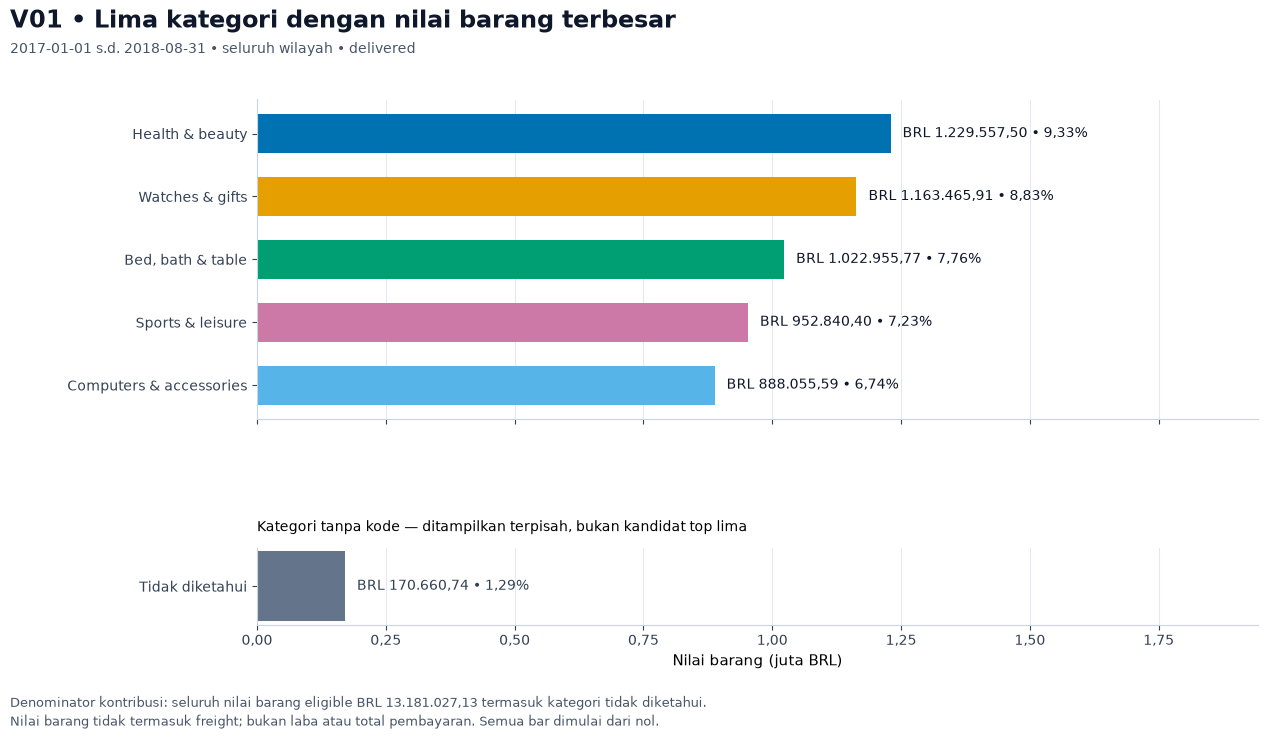

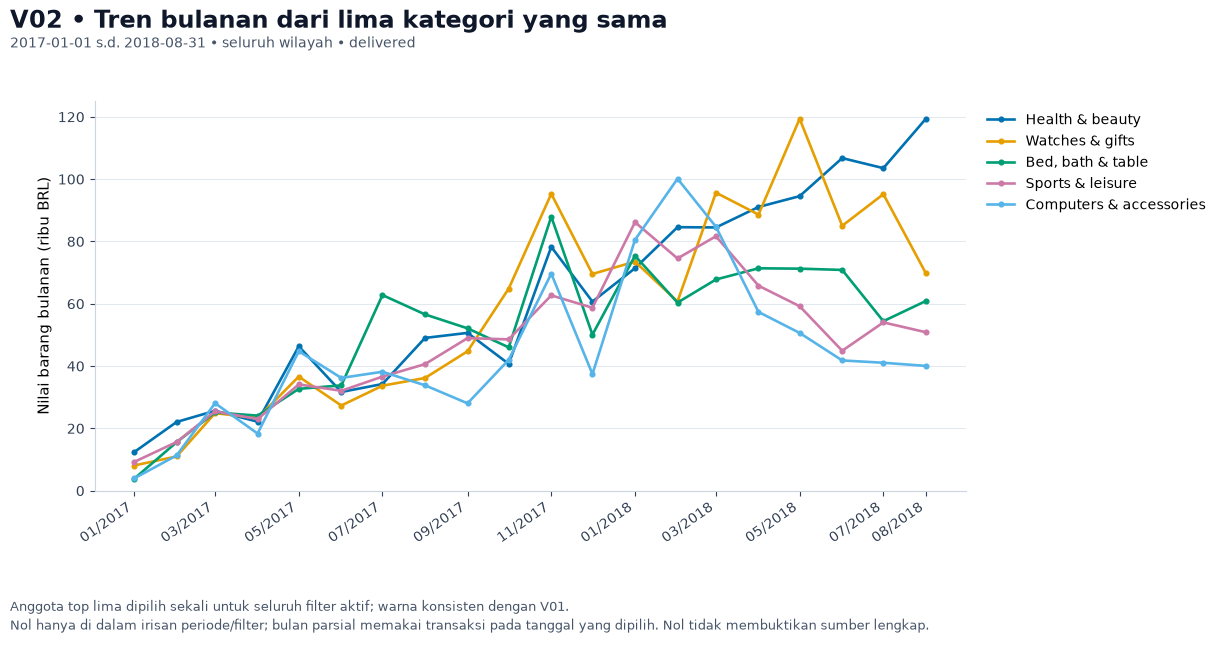

In [13]:
fig = plot_top_categories(q1)
save_figure(fig, FIGURE_DIR / "V01_top_categories.png")
display(fig)
plt.close(fig)
fig = plot_monthly_categories(q1)
save_figure(fig, FIGURE_DIR / "V02_monthly_categories.png")
display(fig)
plt.close(fig)

In [14]:
peak = peaks.loc[peaks["category_code"].eq(q1["top_categories"].iloc[0]["category_code"])].iloc[0]
display(Markdown(f'**Pesan V01–V02:** top lima menyumbang **{number(q1["summary"]["top_five_contribution_pct"],2)}%** dari '
    f'**{brl(q1["summary"]["sales_value_cents"])}**. Kategori tidak diketahui tetap menyumbang '
    f'{number(q1["summary"]["unknown_category_contribution_pct"],2)}%. '
    f'Kategori pertama, **{peak["category_name"]}**, mencapai nilai bulanan maksimum teramati pada **{peak["month"]}**, '
    f'sebesar {brl(peak["sales_value_cents"])}. Ini puncak pada jendela observasi, tanpa asumsi kelengkapan pencatatan.'))

**Pesan V01–V02:** top lima menyumbang **39,88%** dari **BRL 13.181.027,13**. Kategori tidak diketahui tetap menyumbang 1,29%. Kategori pertama, **health_beauty**, mencapai nilai bulanan maksimum teramati pada **2018-08**, sebesar BRL 119.391,01. Ini puncak pada jendela observasi, tanpa asumsi kelengkapan pencatatan.

### Pertanyaan 2:
V03 membandingkan proporsi skor 1–2 dengan n review valid per kelompok. V04 menampilkan lima state prioritas dengan n dan denominator masing-masing panel. State bersampel kecil tidak dihapus dari tabel, tetapi tidak diikutkan dalam peringkat. Ini prioritas investigasi operasional, bukan estimasi sebab-akibat.

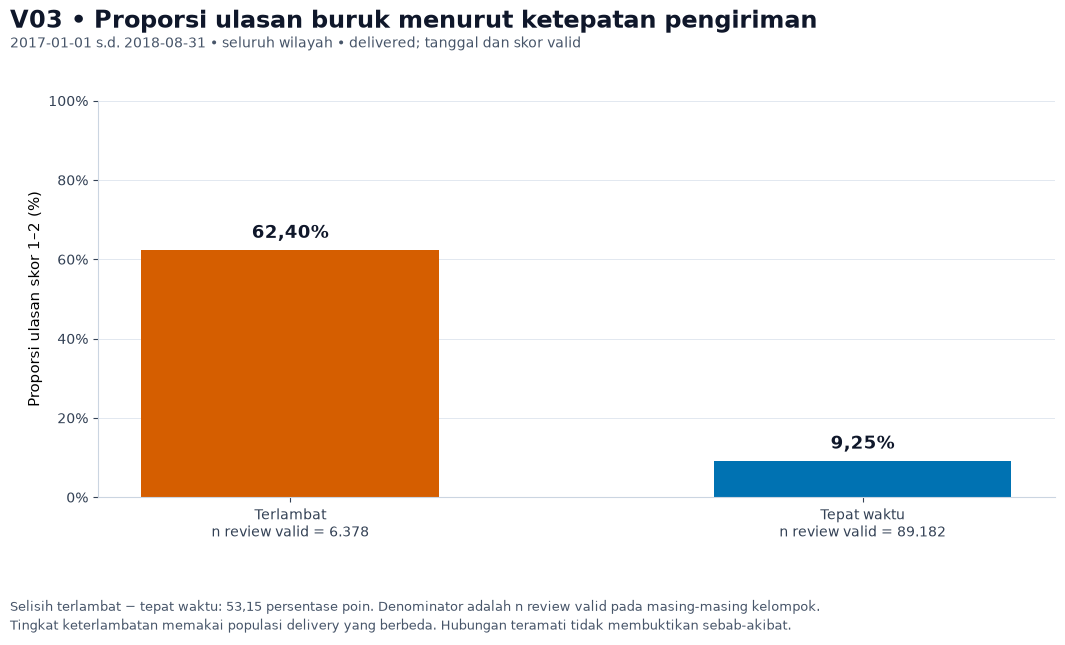

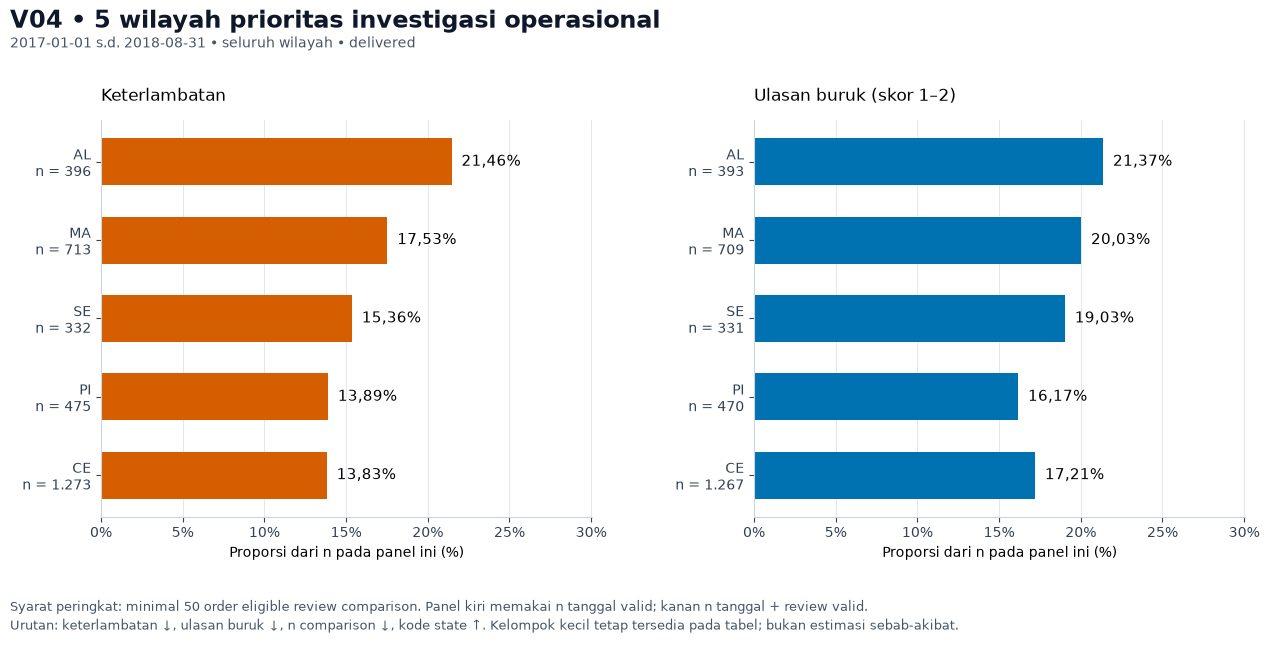

In [15]:
fig = plot_bad_reviews(q2)
save_figure(fig, FIGURE_DIR / "V03_bad_reviews.png")
display(fig)
plt.close(fig)
fig = plot_state_priority(q2)
save_figure(fig, FIGURE_DIR / "V04_state_priority.png")
display(fig)
plt.close(fig)

In [16]:
s = q2["summary"]
display(Markdown(f'**Pesan V03–V04:** proporsi review buruk adalah **{number(s["bad_review_rate_late_pct"],2)}%** '
    f'pada terlambat (n={number(s["comparison_late_orders"])}) versus **{number(s["bad_review_rate_on_time_pct"],2)}%** '
    f'pada tepat waktu (n={number(s["comparison_on_time_orders"])}). Selisihnya **{number(s["bad_review_rate_difference_pp"],2)} persentase poin**. '
    f'Tingkat keterlambatan **{number(s["late_rate_pct"],2)}%** memakai {number(s["delivery_evaluable"])} order; '
    f'{s["delivery_unavailable"]} delivered tanpa tanggal valid dan {s["review_unavailable_among_delivery"]} eligible delivery tanpa review valid dilaporkan terpisah. '
    f'Urutan lima wilayah investigasi: **{", ".join(q2["priority_states"].head(5)["customer_state"])}**.'))

**Pesan V03–V04:** proporsi review buruk adalah **62,40%** pada terlambat (n=6.378) versus **9,25%** pada tepat waktu (n=89.182). Selisihnya **53,15 persentase poin**. Tingkat keterlambatan **6,79%** memakai 96.203 order; 8 delivered tanpa tanggal valid dan 643 eligible delivery tanpa review valid dilaporkan terpisah. Urutan lima wilayah investigasi: **AL, MA, SE, PI, CE**.

**Insight Explanatory:** baca selisih ulasan sebagai persentase poin, bukan perubahan persen relatif. Label n dan coverage diperlukan karena tidak semua delivered mempunyai pasangan tanggal dan review. Peringkat state mengutamakan keterlambatan, lalu ulasan buruk, n comparison, dan kode state, dengan syarat minimum sampel. Tidak ada klaim bahwa state atau keterlambatan menyebabkan ulasan buruk.

## Analisis Lanjutan (Opsional)

### Pertanyaan 3: RFM dan pengelompokan manual
Tujuannya membedakan pendekatan pembelian ulang/retensi. **R** adalah hari kalender sejak pembelian eligible terakhir ke 1 September 2018; **F** order unik; **M** nilai barang dalam sen BRL tanpa freight. Kelima aturan mencakup frequency 1 pada recency ≤30, 31–90, >90 hari, serta frequency ≥2 pada recency ≤90 dan >90 hari. Ini heuristik, tanpa machine learning, bobot skor, atau prediksi churn.

RFM dibangun dari seluruh periode acuan sebelum state difilter. Wilayah mengikuti order eligible terakhir (timestamp lalu order_id), dan R/F/M pelanggan tetap mencakup pembelian di wilayah lain. V05 menunjukkan distribusi tanpa memotong nilai ekstrem; monetary menggunakan sumbu log yang dinyatakan eksplisit.

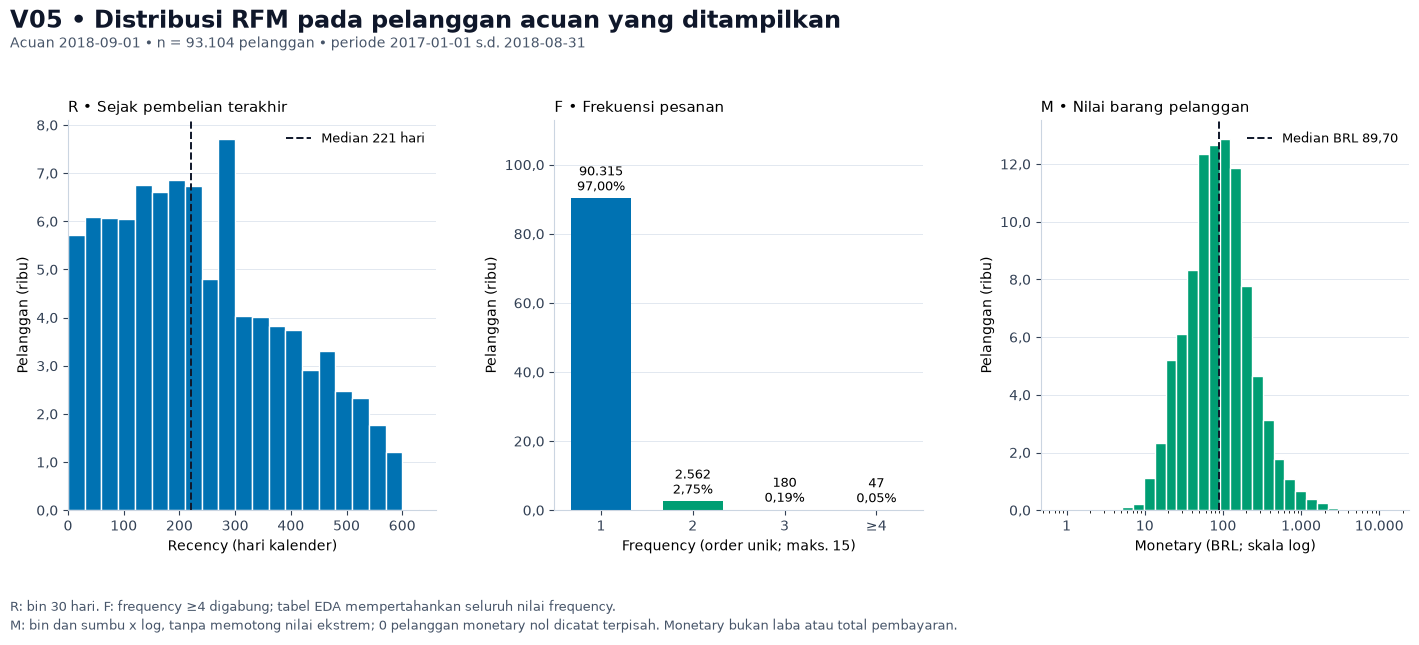

In [17]:
fig = plot_rfm_distributions(rfm_customers, rfm_metadata)
save_figure(fig, FIGURE_DIR / "V05_rfm_distributions.png")
display(fig)
plt.close(fig)

V06 membandingkan **jumlah pelanggan** dengan **kontribusi nilai barang**, bukan dua besaran pada satu sumbu. Semua segmen tetap ditampilkan, termasuk jika suatu filter tidak mempunyai pelanggan di segmen tertentu.

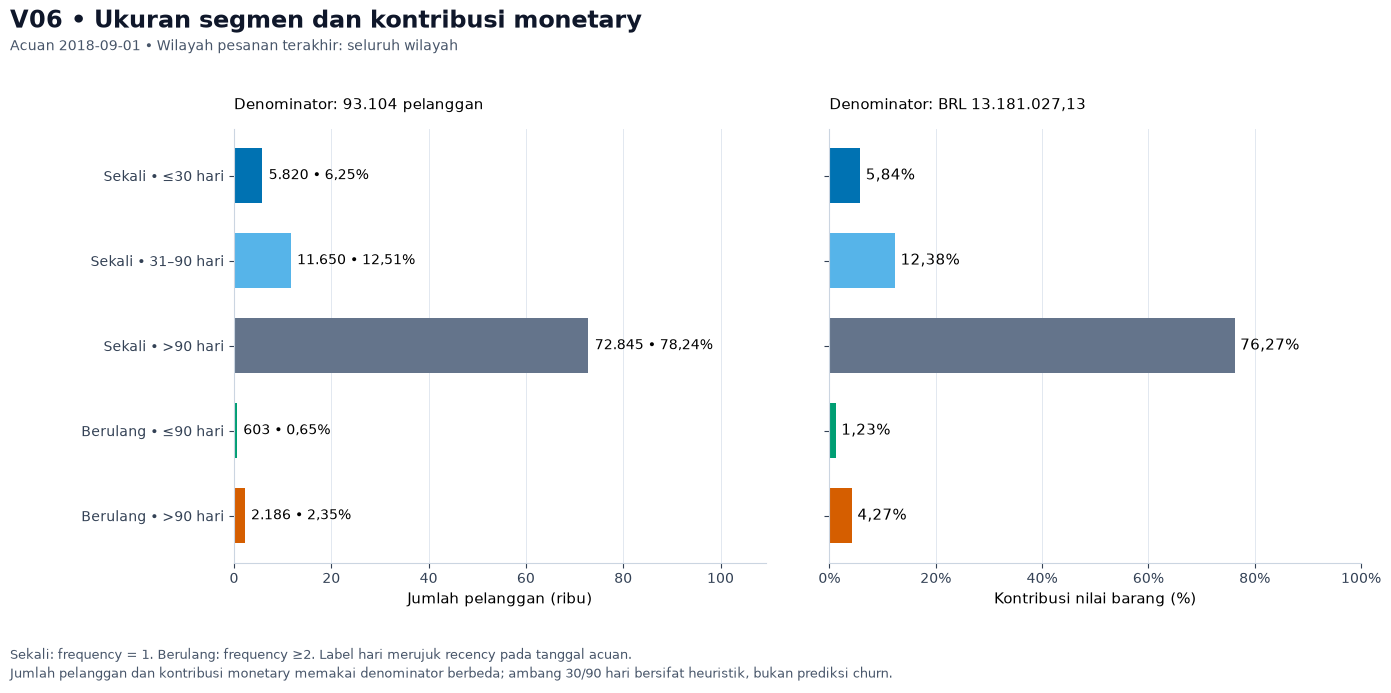

,nilai
ambang global,
quantile,0.75
interpolation,linear
population_customer_count,93104
threshold_cents,15417.5
customers_at_threshold,0
high_value_customers,23276


,customer_count,order_count,monetary_cents,one_time_customers,repeat_customers,repeat_customer_pct,high_value_customers,high_value_customer_pct,filter
0,11877,12312,175141446,11488,389,3.275238,3135,26.395554,Wilayah pesanan terakhir = RJ


In [18]:
fig = plot_rfm_segments(q3)
save_figure(fig, FIGURE_DIR / "V06_rfm_segments.png")
display(fig)
plt.close(fig)
display(pd.Series({k: v for k, v in q3["high_value"].items()
                   if k not in ["threshold_cents_exact", "population", "comparison"]},
                  name="nilai").to_frame().rename_axis("ambang global"))
assert q3["high_value"]["threshold_cents_exact"] == rfm_metadata["high_value"]["threshold_cents_exact"]
# Contoh filter RJ: hanya pelanggan dipilih; cutoff dan seluruh riwayat R/F/M tetap.
q3_rj = analyze_q3(rfm_customers, rfm_metadata, states=["RJ"])
assert q3_rj["high_value"] == q3["high_value"]
display(pd.DataFrame([q3_rj["summary"]]).assign(filter="Wilayah pesanan terakhir = RJ"))

**Insight Analisis Lanjutan:** recency dan pengulangan merupakan hasil jendela observasi historis, bukan diagnosis churn. Cutoff monetary P75 dihitung sekali dari seluruh pelanggan, dengan interpolasi linear; nilai tepat pada ambang termasuk nilai tinggi. Cutoff boleh berupa pecahan sen dan tidak dibulatkan untuk perbandingan. Ties dapat membuat proporsi bernilai tinggi melebihi 25%. Filter wilayah tidak menghitung ulang cutoff; kuartil distribusi deskriptif dalam filter bukan cutoff pengganti.

In [19]:
largest = q3["segments"].sort_values("customer_count", ascending=False).iloc[0]
display(Markdown(f'**Pesan V05–V06:** dari **{number(q3["summary"]["customer_count"])} pelanggan**, '
    f'{number(q3["summary"]["one_time_customers"])} membeli sekali dan {number(q3["summary"]["repeat_customers"])} '
    f'({number(q3["summary"]["repeat_customer_pct"],2)}%) membeli berulang. Segmen terbesar, **{largest["segment"]}**, '
    f'memuat {number(largest["customer_count"])} pelanggan ({number(largest["customer_contribution_pct"],2)}%) dan '
    f'{number(largest["monetary_contribution_pct"],2)}% monetary. Cutoff P75 adalah **{number(q3["high_value"]["threshold_cents"],1)} sen** '
    f'dengan interpolasi {q3["high_value"]["interpolation"]}; perbandingan memakai rasio integer tepat, tanpa pembulatan.'))

**Pesan V05–V06:** dari **93.104 pelanggan**, 90.315 membeli sekali dan 2.789 (3,00%) membeli berulang. Segmen terbesar, **Pembeli sekali yang lama tidak membeli**, memuat 72.845 pelanggan (78,24%) dan 76,27% monetary. Cutoff P75 adalah **15.417,5 sen** dengan interpolasi linear; perbandingan memakai rasio integer tepat, tanpa pembulatan.

## Conclusion & Recommendation

Kesimpulan berikut menjawab ketiga pertanyaan dengan angka hasil eksekusi dan denominator yang dinyatakan. Kesimpulan deskriptif tidak menjanjikan hasil intervensi atau membuktikan hubungan sebab-akibat.

In [20]:
s1, s2, s3 = q1["summary"], q2["summary"], q3["summary"]
top_names = ", ".join(q1["top_categories"]["category_name"])
repeat_old = q3["segments"].set_index("segment").loc[RFM_SEGMENTS[4]]
conclusions = f"""
- **Kesimpulan Q1:** pada 1 Januari 2017–31 Agustus 2018, {number(s1['order_count'])} order delivered eligible memuat nilai barang {brl(s1['sales_value_cents'])}. Lima kategori terbesar adalah **{top_names}**, dengan kontribusi gabungan **{number(s1['top_five_contribution_pct'],2)}%**. Seri V02 mempertahankan kelima kategori yang sama; nilai maksimum kategori pertama teramati pada {peak['month']}. Kategori tidak diketahui menyumbang {number(s1['unknown_category_contribution_pct'],2)}% dan tetap masuk denominator.
- **Kesimpulan Q2:** tingkat keterlambatan **{number(s2['late_rate_pct'],2)}%** memakai n={number(s2['delivery_evaluable'])}. Proporsi review buruk terlambat **{number(s2['bad_review_rate_late_pct'],2)}%** (n={number(s2['comparison_late_orders'])}) dan tepat waktu **{number(s2['bad_review_rate_on_time_pct'],2)}%** (n={number(s2['comparison_on_time_orders'])}), berbeda **{number(s2['bad_review_rate_difference_pp'],2)} persentase poin**. Ini hubungan observasional. Wilayah prioritas menurut aturan dan minimum n={MIN_STATE_SAMPLE} adalah **{', '.join(q2['priority_states'].head(5)['customer_state'])}**; seluruh state termasuk yang di bawah batas sampel tetap ada pada tabel.
- **Kesimpulan Q3:** dengan acuan **{RFM_REFERENCE_DATE}**, {number(s3['customer_count'])} pelanggan terbagi ke lima segmen manual. Pembeli berulang berjumlah **{number(s3['repeat_customers'])} ({number(s3['repeat_customer_pct'],2)}%)**. Segmen terbesar adalah **{largest['segment']}** dengan {number(largest['customer_count'])} pelanggan. Pelanggan berulang yang lama tidak membeli berjumlah {number(repeat_old['customer_count'])}, termasuk {number(repeat_old['high_value_customers'])} bernilai tinggi menurut cutoff global. Ini kandidat pilot retensi, bukan bukti churn. Total frequency {number(s3['order_count'])} dan monetary {brl(s3['monetary_cents'])} cocok dengan order eligible RFM.
"""
display(Markdown(conclusions))


- **Kesimpulan Q1:** pada 1 Januari 2017–31 Agustus 2018, 96.211 order delivered eligible memuat nilai barang BRL 13.181.027,13. Lima kategori terbesar adalah **health_beauty, watches_gifts, bed_bath_table, sports_leisure, computers_accessories**, dengan kontribusi gabungan **39,88%**. Seri V02 mempertahankan kelima kategori yang sama; nilai maksimum kategori pertama teramati pada 2018-08. Kategori tidak diketahui menyumbang 1,29% dan tetap masuk denominator.
- **Kesimpulan Q2:** tingkat keterlambatan **6,79%** memakai n=96.203. Proporsi review buruk terlambat **62,40%** (n=6.378) dan tepat waktu **9,25%** (n=89.182), berbeda **53,15 persentase poin**. Ini hubungan observasional. Wilayah prioritas menurut aturan dan minimum n=50 adalah **AL, MA, SE, PI, CE**; seluruh state termasuk yang di bawah batas sampel tetap ada pada tabel.
- **Kesimpulan Q3:** dengan acuan **2018-09-01**, 93.104 pelanggan terbagi ke lima segmen manual. Pembeli berulang berjumlah **2.789 (3,00%)**. Segmen terbesar adalah **Pembeli sekali yang lama tidak membeli** dengan 72.845 pelanggan. Pelanggan berulang yang lama tidak membeli berjumlah 2.186, termasuk 1.300 bernilai tinggi menurut cutoff global. Ini kandidat pilot retensi, bukan bukti churn. Total frequency 96.211 dan monetary BRL 13.181.027,13 cocok dengan order eligible RFM.


**Rekomendasi Action Item:** setiap tindakan berikut memiliki sasaran dari hasil analisis, cara pelaksanaan, dan indikator evaluasi. Evaluasi pilot membutuhkan pencatatan periode tindak lanjut baru; dataset ini tidak menyediakan eksperimen/intervensi atau outcome setelah jendela observasi.

In [21]:
priority_categories = ", ".join(q1["top_categories"].head(3)["category_name"])
priority_states = ", ".join(q2["priority_states"].head(3)["customer_state"])
display(Markdown(f"""
1. **Katalog/pemasaran — {priority_categories}:** audit ketersediaan produk dan jalankan pilot alokasi katalog/pemasaran dengan anggaran/kelompok pembanding yang setara. **Evaluasi:** nilai barang BRL, item dan order unik per kategori pada periode baru yang sama panjang, serta biaya kampanye yang perlu dikumpulkan. Kontribusi historis bukan jaminan kenaikan penjualan atau laba.
2. **Operasional — {priority_states}:** telusuri order terlambat, estimasi dan lead time aktual sebelum mengubah layanan/estimasi kurir. **Evaluasi:** lateness rate dengan n delivery, proporsi skor 1–2 dengan n comparison, dan coverage tanggal/review sebelum–sesudah pada periode yang sebanding. Temuan saat ini tidak mengisolasi penyebab, sehingga perbaikan harus diuji.
3. **Retensi — pelanggan berulang yang lama tidak membeli:** mulai pilot pada subset bernilai tinggi yang berjumlah **{number(repeat_old['high_value_customers'])} pelanggan** dalam segmen ini; bedakan pesannya dari pembeli sekali. **Evaluasi:** pembelian ulang dan monetary per pelanggan dalam 30/90 hari tindak lanjut baru, dengan kelompok pembanding. Dataset berakhir pada periode acuan dan tidak dapat membuktikan efektivitas pilot tersebut; jangan menganggap label segmen sebagai prediksi churn.
"""))

# Integritas akhir: notebook tidak mengubah CSV sumber atau templat.
for entry in baseline["source_files"]:
    assert sha(ROOT / entry["path"]) == entry["sha256"]
assert sha(ROOT / baseline["template"]["path"]) == baseline["template"]["sha256"]
assert len(list(FIGURE_DIR.glob("V0*.png"))) >= 6
display(Markdown("**Pemeriksaan akhir:** tiga pertanyaan terjawab, enam visual diekspor, nilai/coverage cocok fungsi bersama dan laporan, serta sembilan hash sumber tetap sesuai baseline."))
# Bukti hasil aktual kernel; P10 membandingkan payload ini dengan CSV dan UI.
# Tidak membaca angka dari metadata dashboard atau output notebook sebelumnya.
from src.dashboard_data import jsonable
display({"application/json": {"artifact": "ecommerce.analytics.v1",
    "results": jsonable({"q1": q1, "q2": q2, "q3": q3})},
    "text/plain": "Hasil Q1–Q3 terstruktur tersedia untuk pemeriksaan lintas keluaran."}, raw=True)


1. **Katalog/pemasaran — health_beauty, watches_gifts, bed_bath_table:** audit ketersediaan produk dan jalankan pilot alokasi katalog/pemasaran dengan anggaran/kelompok pembanding yang setara. **Evaluasi:** nilai barang BRL, item dan order unik per kategori pada periode baru yang sama panjang, serta biaya kampanye yang perlu dikumpulkan. Kontribusi historis bukan jaminan kenaikan penjualan atau laba.
2. **Operasional — AL, MA, SE:** telusuri order terlambat, estimasi dan lead time aktual sebelum mengubah layanan/estimasi kurir. **Evaluasi:** lateness rate dengan n delivery, proporsi skor 1–2 dengan n comparison, dan coverage tanggal/review sebelum–sesudah pada periode yang sebanding. Temuan saat ini tidak mengisolasi penyebab, sehingga perbaikan harus diuji.
3. **Retensi — pelanggan berulang yang lama tidak membeli:** mulai pilot pada subset bernilai tinggi yang berjumlah **1.300 pelanggan** dalam segmen ini; bedakan pesannya dari pembeli sekali. **Evaluasi:** pembelian ulang dan monetary per pelanggan dalam 30/90 hari tindak lanjut baru, dengan kelompok pembanding. Dataset berakhir pada periode acuan dan tidak dapat membuktikan efektivitas pilot tersebut; jangan menganggap label segmen sebagai prediksi churn.


**Pemeriksaan akhir:** tiga pertanyaan terjawab, enam visual diekspor, nilai/coverage cocok fungsi bersama dan laporan, serta sembilan hash sumber tetap sesuai baseline.

Hasil Q1–Q3 terstruktur tersedia untuk pemeriksaan lintas keluaran.

### Sumber, atribusi, dan reproduksibilitas

- CSV E-Commerce disediakan secara lokal pada folder data; inventaris/provenance dan SHA-256 tersimpan di reports/baseline.json. Enam sumber utama digunakan; sumber pendukung tidak diunduh ulang.
- Struktur notebook diadaptasi dari [templat resmi Dicoding](https://colab.research.google.com/drive/144WFnMMqvTAnGG-Qj5pUuVAYtCHGJbcp?usp=sharing) yang disalin dan diverifikasi pada P00. Salinan lokal dipertahankan tanpa modifikasi pada references/notebook_template.ipynb.
- Analisis dan visual dihitung melalui kode proyek ini; tidak mengimpor notebook analisis pihak lain. Metode, kebijakan kualitas, dan batas interpretasi dijelaskan pada setiap tahap.
- Ikuti README untuk Python 3.12.13 dan requirements-dev.txt. Jalankan seluruh sel dari kernel bersih di root proyek. Grafik yang sama diekspor ke reports/figures; data dictionary order/item dan RFM tersedia di reports.
- Notebook ini memuat hasil analisis yang telah diverifikasi. Dashboard sudah aktif di [Streamlit Community Cloud](https://y2ybbkygxb92qnxwkgmqsq.streamlit.app/); tautannya juga tersimpan dalam url.txt. Pengemasan dan uji hasil ekstraksi submission diperiksa terpisah sebelum pengiriman.